# P4: Graph and clustering

Turns the candidate pairs of LSH (P2) and embeddings (P3) into one graph, splits it into duplicate clusters
(connected components vs Louvain) and evaluates the clusters with the same metrics as `src/evaluate.py`.

All tuning is on the **dev** split. The test split is used once, in the last section.

| Section | Content |
|---|---|
| 1 | Checks of my own code (modularity, cluster evaluation) |
| 2 | Pair methods on their own (baselines) |
| 3 | Chaining with connected components |
| 4 | Parameter sweep, modularity vs F1, chosen setting |
| 5 | The final graph |
| 6 | The five systems, with time and memory |
| 7 | Recall by word Jaccard |
| 8 | Cluster sizes and purity |
| 9 | Bridge edges |
| 10 | Stability of Louvain across seeds |
| 11 | Final numbers on test |

In [1]:
import sys, gc
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.evaluate import evaluate, recall_by_jaccard_bin
from src.graph import (build_edges, connected_components, louvain, modularity, evaluate_clusters,
                       implied_precision_pairs, recall_by_jaccard_bin_clusters, cluster_sizes,
                       size_summary, cluster_purity, bridges_in_cluster, cluster_to_pairs,
                       run_sweep, choose_setting, Timer)

D = "../data/processed/"
questions = pd.read_parquet(D + "questions.parquet")
pairs = pd.read_parquet(D + "pairs.parquet")
N = len(questions)
assert (questions["qid"].to_numpy() == np.arange(N)).all()   # qids are 0..N-1, used as node ids

lsh_all = pd.read_parquet(D + "lsh_candidates.parquet", columns=["qid_a", "qid_b", "score"])
emb = pd.read_parquet(D + "emb_candidates.parquet", columns=["qid_a", "qid_b", "score"])
print(f"{N:,} questions | LSH candidates {len(lsh_all):,} | embedding candidates {len(emb):,}")

537,174 questions | LSH candidates 26,906,047 | embedding candidates 2,306,347


## 1. Checks of my own code

**Modularity.** `src/graph.modularity` uses the per-community form

$$Q=\sum_c \left[\frac{L_c}{m}-\gamma\left(\frac{d_c}{2m}\right)^2\right]$$

($m$ total edge weight, $L_c$ weight inside community $c$, $d_c$ sum of weighted degrees in $c$).
It runs in O(edges) instead of the double sum over all node pairs.

**Hand example.** Two triangles joined by one edge, each triangle one community:
$m=7$, $L_c=3$, $d_c=2\cdot3+1=7$, so $Q = 2\,(3/7-(7/14)^2)=6/7-1/2\approx0.3571$.

In [2]:
tri = pd.DataFrame({"u": [0, 0, 1, 3, 3, 4, 2], "v": [1, 2, 2, 4, 5, 5, 3], "w": 1.0})
q_hand = 6 / 7 - 1 / 2
q_mine = modularity(tri, np.array([0, 0, 0, 1, 1, 1]))
assert abs(q_mine - q_hand) < 1e-12
print(f"two triangles: by hand {q_hand:.6f} | mine {q_mine:.6f}")

two triangles: by hand 0.357143 | mine 0.357143


**Against NetworkX** on the 10% sample, binary and scaled weights, three resolutions.

**Cluster evaluation.** `src/graph.evaluate_clusters` calls P1's shared `evaluate.evaluate_clusters` (plus implied precision), which gives the metrics of `evaluate` without listing every pair inside a
cluster (a cluster of 10,000 questions has 50 million pairs). It must match `evaluate(cluster_to_pairs(labels))`.

In [3]:
import networkx as nx

sample = pd.read_parquet(D + "questions_sample10.parquet")["qid"].to_numpy()
in_sample = np.zeros(N, bool); in_sample[sample] = True
lsh_s = lsh_all[in_sample[lsh_all.qid_a] & in_sample[lsh_all.qid_b]]
emb_s = emb[in_sample[emb.qid_a] & in_sample[emb.qid_b]]

for weighting in ["binary", "scaled"]:
    E_s = build_edges(lsh_s, emb_s, lsh_threshold=0.8, emb_threshold=0.85, weighting=weighting)
    G = nx.Graph(); G.add_weighted_edges_from(zip(E_s.u, E_s.v, E_s.w))
    for gamma in [0.5, 1, 5]:
        labels = louvain(E_s, N, resolution=gamma, seed=0)
        communities = pd.Series(list(G.nodes)).groupby(labels[list(G.nodes)]).apply(set).tolist()
        mine = modularity(E_s, labels, gamma)
        ref = nx.community.modularity(G, communities, weight="weight", resolution=gamma)
        assert abs(mine - ref) < 1e-9
        print(f"{weighting:7s} gamma={gamma:<4} mine={mine:.10f}  networkx={ref:.10f}")

for name, labels in [("components", connected_components(E_s, N)), ("louvain", louvain(E_s, N, 5, seed=0))]:
    fast = evaluate_clusters(labels, pairs, questions, "dev")
    slow = evaluate(cluster_to_pairs(labels), pairs, questions, "dev")
    assert all(abs(fast[k] - slow[k]) < 1e-12 for k in slow)
    print(name, "evaluate_clusters == evaluate  OK")
del lsh_s, emb_s, E_s, G; _ = gc.collect()

binary  gamma=0.5  mine=0.9919554179  networkx=0.9919554179


binary  gamma=1    mine=0.9847751611  networkx=0.9847751611


binary  gamma=5    mine=0.9362260558  networkx=0.9362260558


scaled  gamma=0.5  mine=0.9945246760  networkx=0.9945246760


scaled  gamma=1    mine=0.9899785903  networkx=0.9899785903


scaled  gamma=5    mine=0.9580273012  networkx=0.9580273012


components evaluate_clusters == evaluate  OK


louvain evaluate_clusters == evaluate  OK


## 2. Pair methods on their own (dev)

`precision` (from P1) only looks at candidates that have a label. `precision_implied` is the share of **all**
predicted pairs that fall inside a true duplicate group. It is a lower bound (unlabelled true duplicates count as
errors), so it is only used to **compare** systems; unlike labelled precision it sees every predicted pair.

Generation time comes from P2/P3's notebooks (their machines): LSH 16.9 s signatures + 191 s banding;
embeddings 191.9 s HNSW index + 157.4 s search (encoding was cached and not timed).

In [4]:
rows = []
def record(name, res, **extra):
    res = dict(res); res.update(system=name, **extra); rows.append(res); return res

union_pairs = pd.concat([lsh_all[["qid_a", "qid_b"]], emb[["qid_a", "qid_b"]]])
for name, cand, gen in [("LSH pairs", lsh_all, 16.9 + 191.2), ("EMB pairs", emb, 191.9 + 157.4),
                        ("Union pairs", union_pairs, 16.9 + 191.2 + 191.9 + 157.4)]:
    record(name, evaluate(cand, pairs, questions, "dev"),
           precision_implied=implied_precision_pairs(cand, questions), generation_sec=gen)
del union_pairs; gc.collect()
pd.DataFrame(rows).set_index("system")[["n_candidates", "recall", "precision", "f1", "recall_implied", "precision_implied"]].round(4)

,n_candidates,recall,precision,f1,recall_implied,precision_implied
system,,,,,,
LSH pairs,26906047,0.3062,0.5218,0.3859,0.2089,0.0017
EMB pairs,2306347,0.8060,0.5997,0.6877,0.6179,0.0613
Union pairs,28824746,0.8198,0.5712,0.6733,0.6293,0.0050


## 3. Chaining: connected components

Graph: nodes are the 537k qids; one edge per candidate pair whose score passes the threshold of its source
(word Jaccard for LSH, cosine for embeddings). Connected components = transitive closure of the edges, so a single
wrong edge merges two whole groups. LSH candidates carry their estimated Jaccard (from 0.07 up), so a Jaccard threshold is
applied here; embedding candidates start at cosine 0.70 (model `msmarco-MiniLM-L6-cos-v5`).

Below: share of all questions in the largest component, on a fine grid of cosine thresholds.

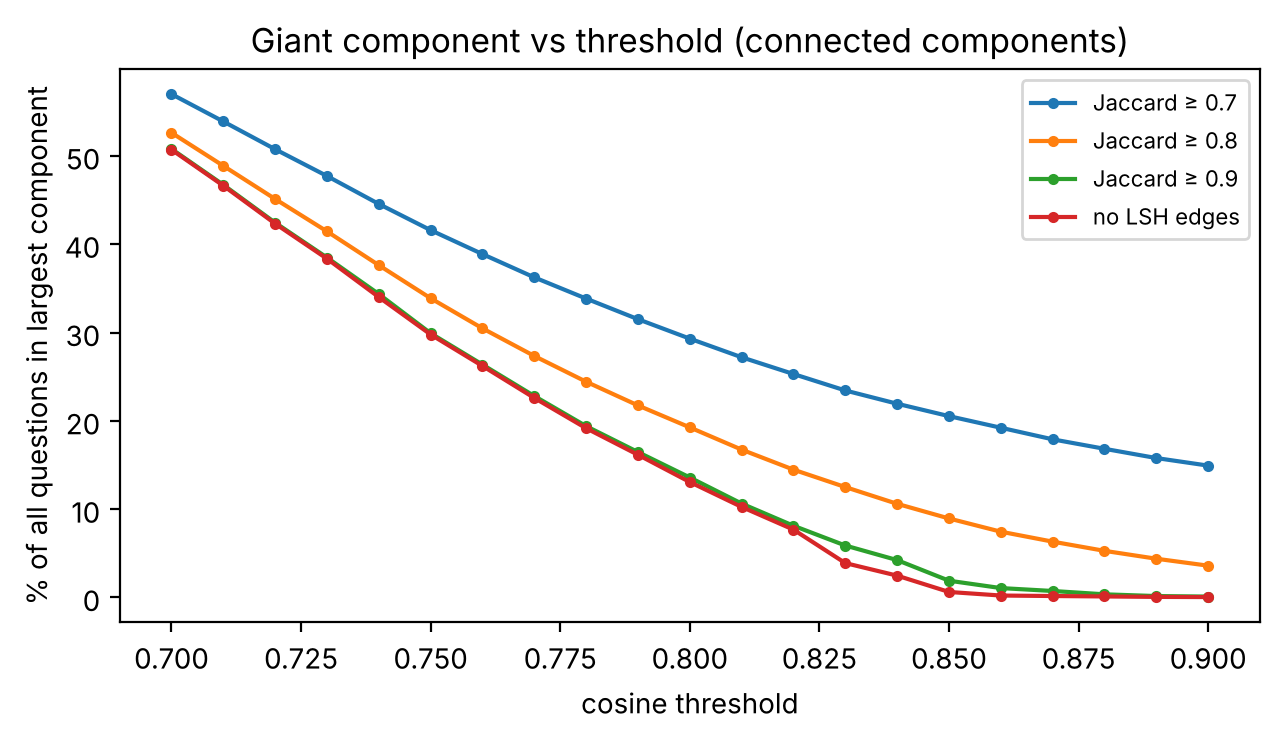

lsh_thr,0.7,0.8,0.9,none
emb_thr,,,,
0.70,56.99,52.62,50.78,50.70
0.71,53.89,48.87,46.72,46.62
0.72,50.75,45.11,42.43,42.32
0.73,47.72,41.45,38.48,38.35
0.74,44.55,37.62,34.35,34.01
0.75,41.59,33.87,29.91,29.77
0.76,38.88,30.47,26.36,26.21
0.77,36.24,27.34,22.80,22.59
0.78,33.84,24.42,19.39,19.16


In [5]:
lsh = lsh_all[lsh_all.score >= 0.6].reset_index(drop=True)      # lower thresholds are never used below
chain = []
for lt in [0.7, 0.8, 0.9, None]:
    for et in np.round(np.arange(0.70, 0.905, 0.01), 2):
        Et = build_edges(lsh if lt else None, emb, lt or 0, et)
        chain.append(dict(lsh_thr=lt or "none", emb_thr=et, edges=len(Et), **size_summary(connected_components(Et, N))))
chain = pd.DataFrame(chain)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for lt, g in chain.groupby("lsh_thr", sort=False):
    ax.plot(g["emb_thr"], g["nodes_in_largest_pct"], marker="o", ms=3, label="no LSH edges" if lt == "none" else f"Jaccard ≥ {lt}")
ax.set_xlabel("cosine threshold"); ax.set_ylabel("% of all questions in largest component")
ax.set_title("Giant component vs threshold (connected components)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
chain.pivot(index="emb_thr", columns="lsh_thr", values="nodes_in_largest_pct").round(2)

## 4. Parameter sweep

For 16 threshold settings (Jaccard 0.6–0.9 × cosine 0.70–0.85): connected components and Louvain with
γ ∈ {1, 5, 20, 100, 300}, 96 partitions in total (`src/graph.run_sweep`). It takes about 35 minutes, so by default
the saved table is reloaded.

In [6]:
RUN_SWEEP = False                      # True = recompute (~35 min) and overwrite the saved table
SWEEP_FILE = D + "p4_sweep_dev.csv"
if RUN_SWEEP:
    sweep = run_sweep(lsh, emb, pairs, questions, split="dev")
    sweep.to_csv(SWEEP_FILE, index=False)
else:
    sweep = pd.read_csv(SWEEP_FILE)
cols = ["method", "lsh_thr", "emb_thr", "gamma", "recall", "precision", "f1", "precision_implied", "largest", "Q1", "sec"]
sweep[cols].sort_values("f1", ascending=False).head(12).round(4)

,method,lsh_thr,emb_thr,gamma,recall,precision,f1,precision_implied,largest,Q1,sec
79,louvain,0.9,0.75,1.0,0.8698,0.6068,0.7149,0.0011,6036,0.9738,6.3493
80,louvain,0.9,0.75,5.0,0.8575,0.6097,0.7127,0.0032,1989,0.9677,5.3385
81,louvain,0.9,0.75,20.0,0.8484,0.6126,0.7115,0.0070,852,0.9501,4.0239
78,components,0.9,0.75,NaN,0.8812,0.5953,0.7106,0.0000,160685,0.3761,0.1905
55,louvain,0.8,0.75,1.0,0.8703,0.5969,0.7082,0.0007,8510,0.9611,5.5721
57,louvain,0.8,0.75,20.0,0.8489,0.6049,0.7064,0.0051,2066,0.8363,4.3705
56,louvain,0.8,0.75,5.0,0.8580,0.5999,0.7061,0.0022,3581,0.9559,6.0949
54,components,0.8,0.75,NaN,0.8848,0.5842,0.7038,0.0000,181966,0.3334,0.3123
73,louvain,0.9,0.70,1.0,0.9292,0.5638,0.7018,0.0004,8698,0.9463,10.3076
74,louvain,0.9,0.70,5.0,0.9141,0.5693,0.7016,0.0012,4175,0.9340,11.3727


### Does modularity agree with F1?

Modularity needs no labels, so if it ranked partitions like F1 it could be used to tune without ground truth.

Careful: the modularity Louvain maximises, $Q_\gamma$, is a **different function for each γ** and always drops when
γ grows, so "$Q_\gamma$ vs γ" says nothing. The fair comparisons are:

- **(a)** standard modularity $Q_1$ (γ = 1) of every partition against its F1;
- **(b)** at a fixed γ, $Q_\gamma$ across threshold settings against F1.

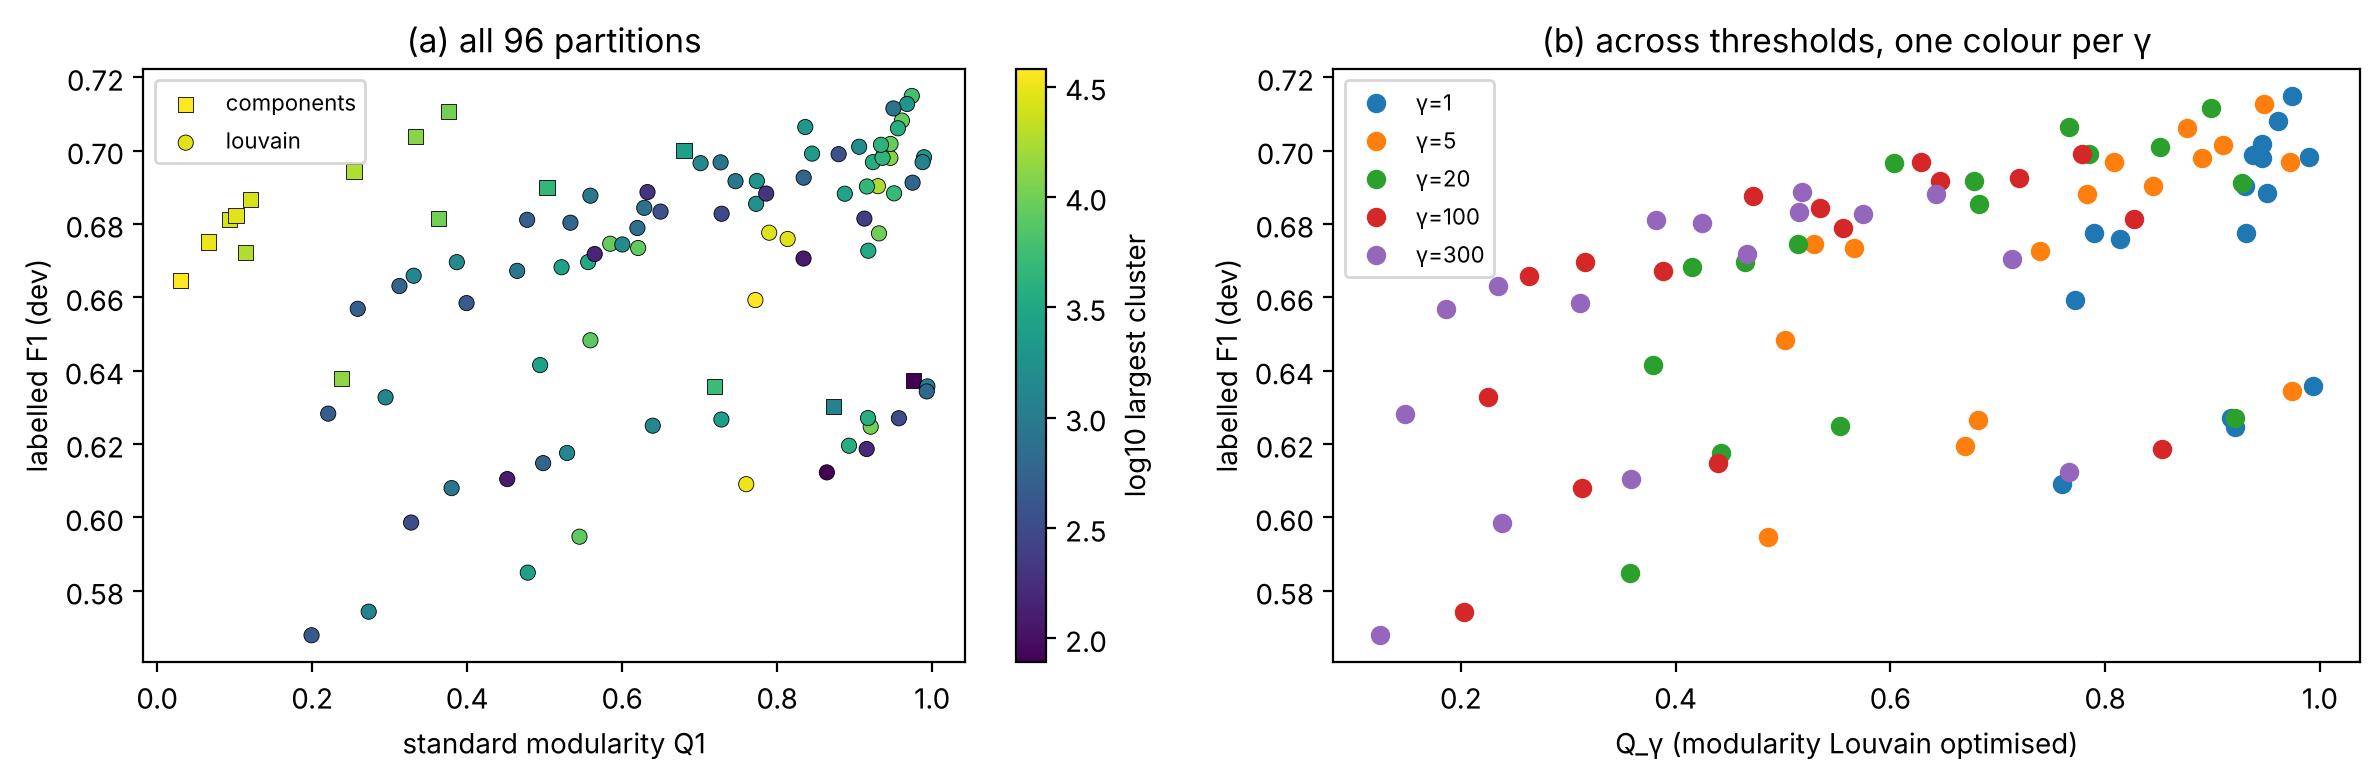

(a) Spearman(Q1, F1) over all partitions: 0.38
    best Q1 : {'method': 'louvain', 'lsh_thr': 0.9, 'emb_thr': 0.85, 'gamma': 1.0, 'Q1': 0.9938677700058643, 'f1': 0.635708603458208}
    best F1 : {'method': 'louvain', 'lsh_thr': 0.9, 'emb_thr': 0.75, 'gamma': 1.0, 'Q1': 0.9737730145480464, 'f1': 0.7148953226012653}
(b) per γ:


,gamma,spearman,best_F1_setting,best_Q_setting
0,1.0,0.61,"(0.9, 0.75)","(0.9, 0.85)"
1,5.0,0.64,"(0.9, 0.75)","(0.9, 0.85)"
2,20.0,0.64,"(0.9, 0.75)","(0.9, 0.8)"
3,100.0,0.62,"(0.9, 0.75)","(0.9, 0.85)"
4,300.0,0.58,"(0.8, 0.75)","(0.9, 0.85)"


In [7]:
from scipy.stats import spearmanr

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method, mk in [("components", "s"), ("louvain", "o")]:
    g = sweep[sweep.method == method]
    sc = axes[0].scatter(g.Q1, g.f1, c=np.log10(g.largest), cmap="viridis", marker=mk, s=30,
                         label=method, edgecolor="k", linewidth=0.3)
plt.colorbar(sc, ax=axes[0], label="log10 largest cluster")
axes[0].set_xlabel("standard modularity Q1"); axes[0].set_ylabel("labelled F1 (dev)")
axes[0].set_title(f"(a) all {len(sweep)} partitions"); axes[0].legend(fontsize=8)

lv = sweep[sweep.method == "louvain"]
corr = []
for gamma, g in lv.groupby("gamma"):
    rho = spearmanr(g.Q_gamma, g.f1).statistic
    corr.append(dict(gamma=gamma, spearman=rho, best_F1_setting=tuple(g.loc[g.f1.idxmax(), ["lsh_thr", "emb_thr"]]),
                     best_Q_setting=tuple(g.loc[g.Q_gamma.idxmax(), ["lsh_thr", "emb_thr"]])))
    axes[1].plot(g.Q_gamma, g.f1, marker="o", linestyle="none", label=f"γ={gamma:g}")
axes[1].set_xlabel("Q_γ (modularity Louvain optimised)"); axes[1].set_ylabel("labelled F1 (dev)")
axes[1].set_title("(b) across thresholds, one colour per γ"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

rho_all = spearmanr(sweep.Q1, sweep.f1).statistic
print(f"(a) Spearman(Q1, F1) over all partitions: {rho_all:.2f}")
print("    best Q1 :", sweep.loc[sweep.Q1.idxmax(), ["method", "lsh_thr", "emb_thr", "gamma", "Q1", "f1"]].to_dict())
print("    best F1 :", sweep.loc[sweep.f1.idxmax(), ["method", "lsh_thr", "emb_thr", "gamma", "Q1", "f1"]].to_dict())
print("(b) per γ:"); pd.DataFrame(corr).round(2)

### Chosen setting

Several settings reach practically the same F1 (differences in the third decimal) while their largest cluster
differs by a factor of 3 or more, and labelled F1 barely penalises big clusters. Rule (`choose_setting`):
**among the settings within 0.005 of the best F1, take the one with the smallest largest cluster.**

In [8]:
TOL = 0.005
best = sweep.loc[sweep.f1.idxmax()]
chosen = choose_setting(sweep, tol=TOL)
print(f"best F1 overall : {best.method} J>={best.lsh_thr} cos>={best.emb_thr} gamma={best.gamma}  F1={best.f1:.4f}  largest={best.largest:,.0f}")
print(f"chosen (tol={TOL}): {chosen.method} J>={chosen.lsh_thr} cos>={chosen.emb_thr} gamma={chosen.gamma}  F1={chosen.f1:.4f}  largest={chosen.largest:,.0f}")
assert chosen.method == "louvain", "the rule picked connected components; the cells below assume Louvain"
LSH_THR, EMB_THR, GAMMA = float(chosen.lsh_thr), float(chosen.emb_thr), float(chosen.gamma)
sweep[sweep.f1 >= best.f1 - TOL][cols].sort_values("largest").round(4)

best F1 overall : louvain J>=0.9 cos>=0.75 gamma=1.0  F1=0.7149  largest=6,036
chosen (tol=0.005): louvain J>=0.9 cos>=0.75 gamma=20.0  F1=0.7115  largest=852


,method,lsh_thr,emb_thr,gamma,recall,precision,f1,precision_implied,largest,Q1,sec
81,louvain,0.9,0.75,20.0,0.8484,0.6126,0.7115,0.0070,852,0.9501,4.0239
80,louvain,0.9,0.75,5.0,0.8575,0.6097,0.7127,0.0032,1989,0.9677,5.3385
79,louvain,0.9,0.75,1.0,0.8698,0.6068,0.7149,0.0011,6036,0.9738,6.3493
78,components,0.9,0.75,NaN,0.8812,0.5953,0.7106,0.0000,160685,0.3761,0.1905


## 5. The final graph

**Weights.** Jaccard and cosine are on different scales (a Jaccard of 0.5 is high, a cosine of 0.5 is low for
MiniLM), so raw scores are not mixed. `binary` gives every edge weight 1; `scaled` rescales each score inside its own
source (threshold → 0.1, score 1 → 1). A pair found by both methods is one edge with `source = "both"`.

In [9]:
with Timer() as t_graph:
    E = build_edges(lsh, emb, LSH_THR, EMB_THR)
print(f"{len(E):,} edges  ({t_graph.seconds:.1f} s)")
print(E["source"].value_counts().to_string())

Es = build_edges(lsh, emb, LSH_THR, EMB_THR, weighting="scaled")
pd.DataFrame({"binary": evaluate_clusters(louvain(E, N, GAMMA, seed=0), pairs, questions, "dev"),
              "scaled": evaluate_clusters(louvain(Es, N, GAMMA, seed=0), pairs, questions, "dev")}).round(4)

1,213,339 edges  (0.3 s)
source
emb     1168524
lsh       28644
both      16171


,binary,scaled
n_candidates,2.471069e+07,2.060715e+07
fraction_of_all_pairs,2.000000e-04,1.000000e-04
labelled_candidates,1.646940e+05,1.643860e+05
recall,8.484000e-01,8.469000e-01
precision,6.126000e-01,6.127000e-01
f1,7.115000e-01,7.110000e-01
recall_implied,7.514000e-01,7.461000e-01
largest_cluster,8.520000e+02,9.480000e+02
n_large_clusters,8.310000e+02,9.340000e+02
fraction_in_large_clusters,2.989000e-01,2.881000e-01


If both weightings give practically the same F1, the simpler binary weights are kept (they are used below).

## 6. The five systems (dev)

For the clustering systems, time and memory are measured here (graph construction + clustering, on top of
the candidates). `peak_mb` is the peak extra process memory, sampled every 20 ms, so it is approximate.
A second Louvain row with another γ (γ = 1, or γ = 20 if γ = 1 was chosen) shows what the choice of γ changes.

In [10]:
del Es; gc.collect()
with Timer() as t_cc:
    labels_cc = connected_components(build_edges(lsh, emb, LSH_THR, EMB_THR), N)
with Timer() as t_lv:
    labels_lv = louvain(build_edges(lsh, emb, LSH_THR, EMB_THR), N, GAMMA, seed=0)
ALT = 20.0 if GAMMA == 1 else 1.0
labels_lv1 = louvain(E, N, ALT, seed=0)

record("Union + components", evaluate_clusters(labels_cc, pairs, questions, "dev"),
       **size_summary(labels_cc), p4_sec=t_cc.seconds, p4_peak_mb=t_cc.peak_mb)
record(f"Union + Louvain (γ={GAMMA:g})", evaluate_clusters(labels_lv, pairs, questions, "dev"),
       **size_summary(labels_lv), p4_sec=t_lv.seconds, p4_peak_mb=t_lv.peak_mb)
record(f"Union + Louvain (γ={ALT:g})", evaluate_clusters(labels_lv1, pairs, questions, "dev"), **size_summary(labels_lv1))

five = pd.DataFrame(rows).set_index("system")
five[["n_candidates", "recall", "precision", "f1", "recall_implied", "precision_implied", "largest",
      "generation_sec", "p4_sec", "p4_peak_mb"]].round(4)

,n_candidates,recall,precision,f1,recall_implied,precision_implied,largest,generation_sec,p4_sec,p4_peak_mb
system,,,,,,,,,,
LSH pairs,26906047,0.3062,0.5218,0.3859,0.2089,0.0017,NaN,208.1,NaN,NaN
EMB pairs,2306347,0.8060,0.5997,0.6877,0.6179,0.0613,NaN,349.3,NaN,NaN
Union pairs,28824746,0.8198,0.5712,0.6733,0.6293,0.0050,NaN,557.4,NaN,NaN
Union + components,12911897761,0.8812,0.5953,0.7106,0.8228,0.0000,160685.0,NaN,0.4934,57.8008
Union + Louvain (γ=20),24710688,0.8484,0.6126,0.7115,0.7514,0.0070,852.0,NaN,4.3980,53.3086
Union + Louvain (γ=1),167000674,0.8698,0.6068,0.7149,0.7985,0.0011,6036.0,NaN,NaN,NaN


`n_candidates` for a clustering is the number of pairs the clusters **imply** ($\sum_c k_c(k_c-1)/2$); they are
counted with the formula, never listed.

## 7. Recall by word Jaccard

Do the clusters recover the paraphrases (low Jaccard) that LSH misses? Comparing the two γ columns checks whether
the gain only comes from very large clusters catching duplicates by chance.

In [11]:
bins = pd.DataFrame({
    "LSH pairs": recall_by_jaccard_bin(lsh_all, pairs, questions, "dev")["recall"],
    "EMB pairs": recall_by_jaccard_bin(emb, pairs, questions, "dev")["recall"],
    "Union + components": recall_by_jaccard_bin_clusters(labels_cc, pairs, questions, "dev")["recall"],
    f"Union + Louvain (γ={ALT:g})": recall_by_jaccard_bin_clusters(labels_lv1, pairs, questions, "dev")["recall"],
    f"Union + Louvain (γ={GAMMA:g})": recall_by_jaccard_bin_clusters(labels_lv, pairs, questions, "dev")["recall"],
})
bins.insert(0, "n_pairs", recall_by_jaccard_bin(emb, pairs, questions, "dev")["n_pairs"])
bins.round(3)

,n_pairs,LSH pairs,EMB pairs,Union + components,Union + Louvain (γ=1),Union + Louvain (γ=20)
bin,,,,,,
"(-0.001, 0.2]",9197,0.000,0.525,0.774,0.757,0.716
"(0.2, 0.4]",42466,0.020,0.683,0.808,0.792,0.762
"(0.4, 0.6]",36385,0.228,0.875,0.912,0.901,0.881
"(0.6, 0.8]",21819,0.833,0.971,0.970,0.965,0.958
"(0.8, 1.0]",9064,0.999,0.995,0.996,0.995,0.993


## 8. Cluster sizes and purity

Purity of a cluster = share of its pairs that lie inside one true duplicate group.

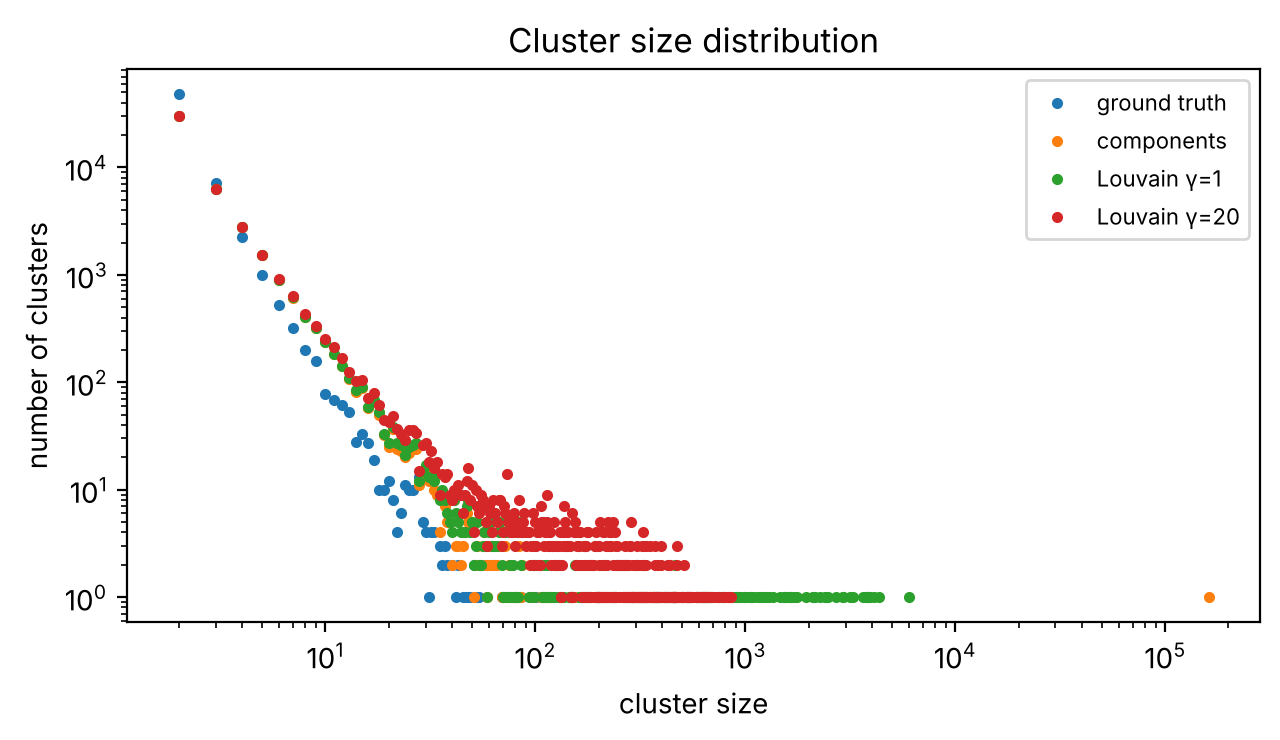

,components,Louvain γ=1,Louvain γ=20
pair-weighted purity,1.463e-05,0.001098,0.006981
"mean purity, clusters ≤ 10",0.4063,0.4063,0.4055
"mean purity, clusters > 100",0.007295,0.004614,0.007126
questions in clusters > 100,1.677e+05,1.626e+05,1.418e+05


,size,pairs,true_pairs,purity
c,,,,
64,852,362526,831,0.002292
18,840,352380,2204,0.006255
289,836,349030,1408,0.004034
1301,830,344035,60,0.0001744
542,797,317206,192,0.0006053
321,785,307720,1136,0.003692
256,743,275653,325,0.001179
509,739,272691,234,0.0008581


In [12]:
truth = cluster_sizes(questions["group_id"].to_numpy())
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, s in [("ground truth", truth), ("components", cluster_sizes(labels_cc)),
                (f"Louvain γ={ALT:g}", cluster_sizes(labels_lv1)), (f"Louvain γ={GAMMA:g}", cluster_sizes(labels_lv))]:
    s = s[s >= 2]; v, c = np.unique(s, return_counts=True)
    ax.loglog(v, c, marker=".", linestyle="none", label=name)
ax.set_xlabel("cluster size"); ax.set_ylabel("number of clusters"); ax.legend(fontsize=8)
ax.set_title("Cluster size distribution"); plt.tight_layout(); plt.show()

purity = {}
for name, lab in [("components", labels_cc), (f"Louvain γ={ALT:g}", labels_lv1), (f"Louvain γ={GAMMA:g}", labels_lv)]:
    pur = cluster_purity(lab, questions)
    small = pur[pur["size"] <= 10]
    purity[name] = {"pair-weighted purity": pur.true_pairs.sum() / pur.pairs.sum(),
                    "mean purity, clusters ≤ 10": small.purity.mean(),
                    "mean purity, clusters > 100": pur[pur["size"] > 100].purity.mean(),
                    "questions in clusters > 100": int(pur[pur["size"] > 100]["size"].sum())}
pd.options.display.float_format = "{:.4g}".format
display(pd.DataFrame(purity))
pur_lv = cluster_purity(labels_lv, questions)
pur_lv.head(8)

## 9. Bridge edges: where the chains break

A bridge is an edge whose removal splits a component. Bridges are counted in the **giant component** of the
final graph and compared with the share of each source among all its edges: if one source is over-represented
among bridges, it is the one that does the chaining.

In [13]:
pd.options.display.float_format = None
text = questions["text_norm"]
giant = pd.Series(labels_cc).value_counts().index[0]
with Timer() as t_br:
    br = bridges_in_cluster(E, labels_cc, giant)
in_giant = (labels_cc[E.u.to_numpy()] == giant)
share = pd.DataFrame({"all edges in giant": E[in_giant]["source"].value_counts(normalize=True),
                      "bridges": br["source"].value_counts(normalize=True),
                      "bridges splitting off ≥ 5": br[br.smaller_side >= 5]["source"].value_counts(normalize=True)}).fillna(0)
print(f"giant component: {(labels_cc == giant).sum():,} questions, {in_giant.sum():,} edges, "
      f"{len(br):,} bridges ({(br.smaller_side >= 5).sum():,} split off ≥ 5 questions)  [{t_br.seconds:.0f} s]")
display(share.round(3))
for _, b in br.head(4).iterrows():
    print(f"\n[{b.source}] removing it splits off {b.smaller_side} questions")
    print("   A:", text[b.u]); print("   B:", text[b.v])

giant component: 160,685 questions, 957,938 edges, 25,376 bridges (1,818 split off ≥ 5 questions)  [11 s]


,all edges in giant,bridges,bridges splitting off ≥ 5
source,,,
both,0.006,0.008,0.004
emb,0.990,0.985,0.984
lsh,0.003,0.007,0.012



[emb] removing it splits off 598 questions
   A: do you think trump can cause the third world war?
   B: what can cause third world war?

[emb] removing it splits off 346 questions
   A: what's the best way to potty train a dog?
   B: what is the best way to get a dog?

[emb] removing it splits off 324 questions
   A: how do i invest in mutual funds?
   B: how does one invest in mutual funds? what are the pros and cons of investing in a mutual fund?

[emb] removing it splits off 323 questions
   A: what are the pros and cons of investing in stocks, equity, and mutual funds?
   B: how does one invest in mutual funds? what are the pros and cons of investing in a mutual fund?


## 10. Stability of Louvain across seeds

Louvain is randomised. Five seeds on the chosen setting.

In [14]:
stab = []
for seed in range(5):
    lab = louvain(E, N, GAMMA, seed=seed)
    stab.append(dict(seed=seed, **evaluate_clusters(lab, pairs, questions, "dev"), largest=size_summary(lab)["largest"],
                     Q=modularity(E, lab, GAMMA)))
stab = pd.DataFrame(stab)
print(stab[["recall", "precision", "f1", "largest", "Q"]].agg(["mean", "std", "min", "max"]).round(4).to_string())

      recall  precision      f1    largest       Q
mean  0.8477     0.6127  0.7113   947.2000  0.8985
std   0.0005     0.0001  0.0002    69.8477  0.0001
min   0.8470     0.6126  0.7110   852.0000  0.8983
max   0.8484     0.6128  0.7115  1018.0000  0.8986


## 11. Final numbers on test (run once)

Run once, after every setting (thresholds, γ, weights) was fixed on dev: Jaccard ≥ 0.9, cosine ≥ 0.75, Louvain γ = 20.

In [15]:
RUN_TEST = True
if RUN_TEST:
    cols_t = ["n_candidates", "recall", "precision", "f1", "recall_implied", "precision_implied", "largest_cluster"]
    union_t = pd.concat([lsh_all[["qid_a", "qid_b"]], emb[["qid_a", "qid_b"]]])
    test = pd.DataFrame({
        "LSH pairs": dict(evaluate(lsh_all, pairs, questions, "test"), precision_implied=implied_precision_pairs(lsh_all, questions)),
        "EMB pairs": dict(evaluate(emb, pairs, questions, "test"), precision_implied=implied_precision_pairs(emb, questions)),
        "Union pairs": dict(evaluate(union_t, pairs, questions, "test"), precision_implied=implied_precision_pairs(union_t, questions)),
        "Union + components": evaluate_clusters(labels_cc, pairs, questions, "test"),
        f"Union + Louvain (γ={GAMMA:g})": evaluate_clusters(labels_lv, pairs, questions, "test"),
    }).T
    display(test.reindex(columns=cols_t).round(4))

,n_candidates,recall,precision,f1,recall_implied,precision_implied,largest_cluster
LSH pairs,2.690605e+07,0.2863,0.4999,0.3641,0.1892,0.0017,NaN
EMB pairs,2.306347e+06,0.8051,0.6060,0.6915,0.6133,0.0613,NaN
Union pairs,2.882475e+07,0.8163,0.5735,0.6737,0.6217,0.0050,NaN
Union + components,1.291190e+10,0.8825,0.6039,0.7171,0.8300,0.0000,160685.0
Union + Louvain (γ=20),2.471069e+07,0.8447,0.6179,0.7137,0.7569,0.0070,852.0


### Research question on test

How many labelled test duplicates LSH misses, and how many of those the embeddings and the clusters recover.

In [16]:
if RUN_TEST:
    t = pairs[(pairs.split == "test") & (pairs.is_duplicate == 1)]
    key = lambda a, b: np.minimum(a, b) * N + np.maximum(a, b)
    k_true = key(t.qid1.to_numpy(), t.qid2.to_numpy())
    in_lsh = np.isin(k_true, key(lsh_all.qid_a.to_numpy(), lsh_all.qid_b.to_numpy()))
    in_emb = np.isin(k_true, key(emb.qid_a.to_numpy(), emb.qid_b.to_numpy()))
    in_lv = labels_lv[t.qid1.to_numpy()] == labels_lv[t.qid2.to_numpy()]
    missed = ~in_lsh
    print(f"labelled test duplicate pairs: {len(t):,}")
    print(f"missed by LSH: {missed.sum():,} ({missed.mean():.1%})")
    print(f"  recovered by embedding pairs: {(in_emb & missed).sum():,} ({in_emb[missed].mean():.1%})")
    print(f"  recovered by Union + Louvain: {(in_lv & missed).sum():,} ({in_lv[missed].mean():.1%})")
    print(f"found by Louvain but in no embedding pair: {(in_lv & ~in_emb).sum():,} | in an embedding pair but split by Louvain: {(in_emb & ~in_lv).sum():,}")

    bins_t = pd.DataFrame({
        "LSH pairs": recall_by_jaccard_bin(lsh_all, pairs, questions, "test")["recall"],
        "EMB pairs": recall_by_jaccard_bin(emb, pairs, questions, "test")["recall"],
        "Union + components": recall_by_jaccard_bin_clusters(labels_cc, pairs, questions, "test")["recall"],
        f"Union + Louvain (γ={GAMMA:g})": recall_by_jaccard_bin_clusters(labels_lv, pairs, questions, "test")["recall"],
    })
    bins_t.insert(0, "n_pairs", recall_by_jaccard_bin(emb, pairs, questions, "test")["n_pairs"])
    display(bins_t.round(3))

labelled test duplicate pairs: 29,842
missed by LSH: 21,299 (71.4%)
  recovered by embedding pairs: 15,816 (74.3%)
  recovered by Union + Louvain: 17,068 (80.1%)
found by Louvain but in no embedding pair: 2,493 | in an embedding pair but split by Louvain: 1,311


,n_pairs,LSH pairs,EMB pairs,Union + components,Union + Louvain (γ=20)
bin,,,,,
"(-0.001, 0.2]",2726,0.000,0.491,0.788,0.716
"(0.2, 0.4]",11274,0.019,0.698,0.817,0.763
"(0.4, 0.6]",8709,0.234,0.897,0.918,0.888
"(0.6, 0.8]",5137,0.836,0.977,0.973,0.961
"(0.8, 1.0]",1996,0.999,0.996,0.994,0.991
